# Fase 8c — Generalización geográfica: Lima y Bolivia (entregable 4)

**Enunciado:** entrenar solo con Sen1Floods11 (✔ el modelo final nunca vio Lima ni Bolivia), evaluar en la región de Lima y **reportar la brecha frente al punto 3 (test)**, proponiendo al menos dos hipótesis.

**Protocolo:**
- Modelo final de la fase 7 (`solo_dorados`, pérdida combinada), **3 semillas**, umbral **0.5** (sin reajustar nada para Lima ni Bolivia).
- Regiones: **test** (en distribución, resultados de la fase 7) · **Bolivia** (evento no visto, partición oficial) · **Lima** (región peruana construida en la 8b).
- Referencia clásica: **Otsu** (Bolivia: fase 4; Lima: Otsu sobre VH en cada chip).
- **Brecha** = IoU(test) − IoU(región), absoluta y relativa.

**Corrección de datos:** los píxeles de Lima con VV = VH = 0 dB exactos (sin dato del borde de la franja) se marcan como −1 al leerlos. No se modifica ningún archivo.

Corre en CPU (~20–30 min) o más rápido con GPU.

## 0. Preparación

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio scikit-image

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Módulo nuevo: `src/evaluacion_lima.py`

In [5]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/evaluacion_lima.py
"""
evaluacion_lima.py
Fase 8c (entregable 4): generalización geográfica.
  - ConjuntoLima: lee los chips de Lima con el MISMO preprocesamiento que Sen1Floods11, y además
    marca como -1 los píxeles con VV = VH = 0 dB exactos (sin dato que Earth Engine devolvió como 0
    en el borde de la franja del satélite). No modifica los archivos en disco.
  - Otsu por chip sobre VH como referencia clásica en Lima.
  - Evaluación de las 3 semillas del modelo final en cualquier región (test, Bolivia, Lima).
"""
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from .conjunto_datos import ConjuntoInundaciones
from .configuracion import RAIZ_PROYECTO, VALOR_SIN_DATO
from .entrenamiento import cargar_mejor_modelo
from .evaluacion_final import evaluar_con_histograma, curva_umbral
from .lectura import leer_s1, leer_etiqueta
from .metricas_torch import AcumuladorConfusion

DIR_CHIPS_LIMA = RAIZ_PROYECTO / "datos_lima" / "chips"
DIR_S1_LIMA, DIR_ETIQUETA_LIMA = DIR_CHIPS_LIMA / "S1Hand", DIR_CHIPS_LIMA / "LabelHand"


def ids_lima():
    return sorted(r.name.replace("_S1Hand.tif", "") for r in DIR_S1_LIMA.glob("*_S1Hand.tif"))


def mascara_ceros(s1):
    """True donde VV y VH valen exactamente 0 dB (sin dato)."""
    return (s1 == 0).all(axis=0)


class ConjuntoLima(ConjuntoInundaciones):
    def __init__(self, ids_chips, normalizador, **parametros):
        super().__init__(ids_chips, normalizador, dir_s1=DIR_S1_LIMA, sufijo_s1="S1Hand",
                         dir_etiqueta=DIR_ETIQUETA_LIMA, sufijo_etiqueta="LabelHand", **parametros)

    def _cargar(self, id_chip):
        imagen, etiqueta = super()._cargar(id_chip)
        s1 = leer_s1(id_chip, self.dir_s1, self.sufijo_s1)
        etiqueta[mascara_ceros(s1)] = VALOR_SIN_DATO
        return imagen, etiqueta


def cargador_lima(normalizador, tamano_lote=4, num_workers=2):
    conjunto = ConjuntoLima(ids_lima(), normalizador)
    return DataLoader(conjunto, batch_size=tamano_lote, shuffle=False, num_workers=num_workers)


def diagnostico_ceros() -> pd.DataFrame:
    filas = []
    for id_chip in ids_lima():
        s1 = leer_s1(id_chip, DIR_S1_LIMA, "S1Hand")
        etiqueta = leer_etiqueta(id_chip, DIR_ETIQUETA_LIMA, "LabelHand")
        ceros = mascara_ceros(s1)
        filas.append({"id_chip": id_chip, "px_cero": int(ceros.sum()), "pct_chip": 100 * ceros.mean(),
                      "px_cero_etiquetados_agua": int((ceros & (etiqueta == 1)).sum()),
                      "px_cero_etiquetados_no_agua": int((ceros & (etiqueta == 0)).sum())})
    return pd.DataFrame(filas)


# ----------------------------------------------------------------------------- referencia clásica
def otsu_lima(conjunto) -> AcumuladorConfusion:
    """Umbral de Otsu sobre VH (dB) en cada chip; agua = VH < umbral. Mismos píxeles ignorados que la U-Net."""
    from skimage.filters import threshold_otsu
    acumulador = AcumuladorConfusion()
    for i, id_chip in enumerate(conjunto.ids_chips):
        _, etiqueta, _ = conjunto[i]
        vh = leer_s1(id_chip, conjunto.dir_s1, conjunto.sufijo_s1)[1]
        validos = np.isfinite(vh) & (etiqueta.numpy() != VALOR_SIN_DATO)
        if validos.sum() < 100:
            continue
        umbral = threshold_otsu(vh[validos])
        logits = torch.from_numpy(np.where(np.nan_to_num(vh, nan=0) < umbral, 10.0, -10.0)).float()
        acumulador.actualizar(logits[None], etiqueta[None], [id_chip])
    return acumulador


# ----------------------------------------------------------------------------- U-Net en varias regiones
def evaluar_regiones(carpeta, semillas, cargadores: dict, dir_experimentos, dispositivo) -> dict:
    """cargadores = {'bolivia': DataLoader, 'lima': DataLoader, ...}. Umbral 0.5 + curvas IoU-umbral."""
    salida = {"filas": [], "acumuladores": {r: {} for r in cargadores}, "curvas": {r: {} for r in cargadores}}
    for semilla in semillas:
        modelo, _, _ = cargar_mejor_modelo(dir_experimentos / f"{carpeta}_s{semilla}", dispositivo)
        for region, cargador in cargadores.items():
            acumulador, hist_agua, hist_no_agua = evaluar_con_histograma(modelo, cargador, dispositivo)
            salida["filas"].append({"region": region, "semilla": semilla, **acumulador.metricas()})
            salida["acumuladores"][region][semilla] = acumulador
            salida["curvas"][region][semilla] = curva_umbral(hist_agua, hist_no_agua)
        del modelo
    salida["df"] = pd.DataFrame(salida["filas"])
    return salida


Overwriting /content/drive/MyDrive/rnap_p2_inundaciones/src/evaluacion_lima.py


## 2. Imports y datos

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.configuracion import *
from src.utilidades import fijar_semilla, obtener_dispositivo
from src.descarga import descargar_mano
from src.preprocesamiento import Normalizador
from src.cargadores import crear_cargadores
from src.lectura import leer_s1
from src.evaluacion import predecir_probabilidades
from src.evaluacion_final import CARPETAS, elegir_variante, matriz_sumada
from src.evaluacion_lima import (ids_lima, ConjuntoLima, cargador_lima, diagnostico_ceros, otsu_lima,
                                 evaluar_regiones, mascara_ceros, DIR_S1_LIMA, DIR_ETIQUETA_LIMA)
from src.visualizacion_metricas import figura_matriz_confusion
from src.visualizacion_final import figura_errores

dispositivo = obtener_dispositivo()
fijar_semilla(SEMILLA)
descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')
cargadores = crear_cargadores(normalizador, tamano_lote=4, tamano_recorte=256, num_workers=2, semilla=SEMILLA)
cargadores_eval = {'bolivia': cargadores['bolivia'], 'lima': cargador_lima(normalizador)}
linea_base_otsu = pd.read_csv(DIR_RESULTADOS / 'f4_linea_base_otsu.csv', index_col=0)
DIR_EXPERIMENTOS, SEMILLAS = DIR_RESULTADOS / 'experimentos', [42, 7, 123]
variante_final, _ = elegir_variante(DIR_RESULTADOS / 'f6a_ablacion_corridas.csv')
carpeta_final = CARPETAS[variante_final]
print('Modelo final:', variante_final, '| chips Lima:', len(ids_lima()))

OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU
[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


Cargando chips en RAM:   0%|          | 0/252 [00:00<?, ?it/s]

train   : 252 chips ->  63 lotes


Cargando chips en RAM:   0%|          | 0/89 [00:00<?, ?it/s]

valid   :  89 chips ->  45 lotes


...

test    :  90 chips ->  45 lotes


Cargando chips en RAM:   0%|          | 0/15 [00:00<?, ?it/s]

bolivia :  15 chips ->   8 lotes


Cargando chips en RAM:   0%|          | 0/64 [00:00<?, ?it/s]

Modelo final: solo_dorados | chips Lima: 64


## 3. Diagnóstico de los píxeles en 0 dB (sin dato)

In [7]:
diag = diagnostico_ceros()
diag.to_csv(DIR_RESULTADOS / 'f8_diagnostico_ceros_lima.csv', index=False)
afectados = diag[diag['px_cero'] > 0]
print(f"Chips con píxeles en 0 dB: {len(afectados)} de {len(diag)} | píxeles: {diag['px_cero'].sum():,}"
      f" (etiquetados agua: {diag['px_cero_etiquetados_agua'].sum():,}, no agua: {diag['px_cero_etiquetados_no_agua'].sum():,})")
afectados.sort_values('px_cero', ascending=False).head(10).round(2)

Chips con píxeles en 0 dB: 15 de 64 | píxeles: 2,567,606 (etiquetados agua: 0, no agua: 2,128,619)


,id_chip,px_cero,pct_chip,px_cero_etiquetados_agua,px_cero_etiquetados_no_agua
0,Lima_0000,262144,100.00,0,90248
16,Lima_0200,262144,100.00,0,255797
8,Lima_0100,262144,100.00,0,254463
32,Lima_0400,262144,100.00,0,258468
24,Lima_0300,262144,100.00,0,257097
1,Lima_0001,249860,95.31,0,97198
40,Lima_0500,237641,90.65,0,235261
9,Lima_0101,197492,75.34,0,197492
48,Lima_0600,182267,69.53,0,181230
17,Lima_0201,142016,54.17,0,142016


### Distribución corregida (sin los 0 dB): Lima vs. Sen1Floods11 train
Reemplaza la tabla de la fase 8b para el informe.

Muestreando píxeles:   0%|          | 0/252 [00:00<?, ?it/s]

vv         vh
region             clase                    
Lima 17/03/2017    agua    -10.79 -18.639999
                   no agua -10.14 -17.770000
Sen1Floods11 train agua    -14.92 -23.000000
                   no agua  -9.58 -16.030001

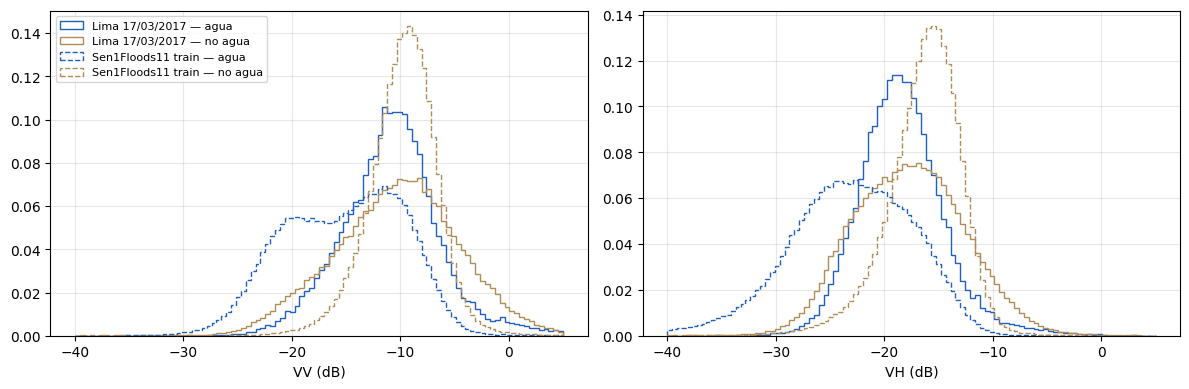

In [8]:
from src.exploracion import muestrear_pixeles
from src.lectura import leer_particion

pix_train = muestrear_pixeles(leer_particion('train')['id_chip'], n_por_clase=2000, semilla=SEMILLA)
pix_train['region'] = 'Sen1Floods11 train'
conjunto_lima = ConjuntoLima(ids_lima(), normalizador, en_memoria=False)
generador, partes = np.random.default_rng(SEMILLA), []
for i, id_chip in enumerate(conjunto_lima.ids_chips):
    s1 = leer_s1(id_chip, DIR_S1_LIMA, 'S1Hand')
    etiqueta = conjunto_lima[i][1].numpy()                    # ya con 0 dB y NaN como -1
    for clase in (0, 1):
        f, c = np.where(etiqueta == clase)
        if len(f):
            k = generador.choice(len(f), min(2000, len(f)), replace=False)
            partes.append(pd.DataFrame({'vv': s1[0, f[k], c[k]], 'vh': s1[1, f[k], c[k]], 'clase': clase}))
pix_lima = pd.concat(partes); pix_lima['region'] = 'Lima 17/03/2017'
pixeles = pd.concat([pix_train, pix_lima]); pixeles['clase'] = pixeles['clase'].map({0: 'no agua', 1: 'agua'})
tabla_dist = pixeles.groupby(['region', 'clase'])[['vv', 'vh']].median().round(2)
tabla_dist.to_csv(DIR_RESULTADOS / 'f8_distribucion_lima_vs_train_corregida.csv')
display(tabla_dist)

figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, banda in zip(ejes, ['vv', 'vh']):
    for (region, clase), grupo in pixeles.groupby(['region', 'clase']):
        eje.hist(grupo[banda], bins=100, range=(-40, 5), density=True, histtype='step', lw=1.8,
                 linestyle='-' if region.startswith('Lima') else '--',
                 color='#1f5fbf' if clase == 'agua' else '#b08d57', label=f'{region} — {clase}')
    eje.set_xlabel(f'{banda.upper()} (dB)'); eje.grid(alpha=0.3)
ejes[0].legend(fontsize=8); figura.tight_layout()
figura.savefig(DIR_FIGURAS / 'f8_distribucion_lima_vs_train_corregida.png', dpi=150, bbox_inches='tight')

## 4. U-Net en Bolivia y Lima (3 semillas, umbral 0.5)

In [9]:
salida = evaluar_regiones(carpeta_final, SEMILLAS, cargadores_eval, DIR_EXPERIMENTOS, dispositivo)
df_regiones = salida['df']
df_regiones.to_csv(DIR_RESULTADOS / 'f8_regiones_por_semilla.csv', index=False)
df_regiones[['region', 'semilla', 'iou', 'f1', 'precision', 'recall', 'omision', 'comision']].round(4)

,region,semilla,iou,f1,precision,recall,omision,comision
0,bolivia,42,0.6462,0.7851,0.8846,0.7057,0.2943,0.1154
1,lima,42,0.0037,0.0074,0.0050,0.0145,0.9855,0.9950
2,bolivia,7,0.6931,0.8187,0.8703,0.7729,0.2271,0.1297
3,lima,7,0.0022,0.0043,0.0026,0.0126,0.9874,0.9974
4,bolivia,123,0.6508,0.7885,0.8948,0.7047,0.2953,0.1052
5,lima,123,0.0034,0.0068,0.0039,0.0267,0.9733,0.9961


## 5. Otsu en Lima (referencia clásica)

In [10]:
acumulador_otsu_lima = otsu_lima(conjunto_lima)
otsu_lima_metricas = acumulador_otsu_lima.metricas()
pd.Series(otsu_lima_metricas).round(3)

,0
iou,0.011
f1,0.022
precision,0.011
recall,0.445
omision,0.555
comision,0.989
exactitud,0.492


## 6. Tabla de la brecha (resultado principal del entregable 4)

In [11]:
metricas = ['iou', 'f1', 'precision', 'recall', 'omision', 'comision']
df_test = pd.read_csv(DIR_RESULTADOS / 'f7_test_por_semilla.csv')
df_test = df_test[df_test['criterio_umbral'] == 'fijo 0.5'].assign(region='test')
todo = pd.concat([df_test[['region', 'semilla'] + metricas], df_regiones[['region', 'semilla'] + metricas]])

media = todo.groupby('region', sort=False)[metricas].mean()
desv = todo.groupby('region', sort=False)['iou'].std()
otsu = {'test': linea_base_otsu.loc['test', 'iou'], 'bolivia': linea_base_otsu.loc['bolivia', 'iou'],
        'lima': otsu_lima_metricas['iou']}
tabla_brecha = media.copy()
tabla_brecha.insert(1, 'iou_desv', desv)
tabla_brecha['iou_otsu'] = pd.Series(otsu)
tabla_brecha['brecha_iou_vs_test'] = media.loc['test', 'iou'] - media['iou']
tabla_brecha['brecha_relativa_%'] = 100 * tabla_brecha['brecha_iou_vs_test'] / media.loc['test', 'iou']
tabla_brecha['unet_menos_otsu'] = media['iou'] - tabla_brecha['iou_otsu']
tabla_brecha.to_csv(DIR_RESULTADOS / 'f8_tabla_brecha.csv')
tabla_brecha.round(3)

,iou,iou_desv,f1,precision,recall,omision,comision,iou_otsu,brecha_iou_vs_test,brecha_relativa_%,unet_menos_otsu
region,,,,,,,,,,,
test,0.669,0.003,0.801,0.815,0.789,0.211,0.185,0.554,0.000,0.000,0.114
bolivia,0.663,0.026,0.797,0.883,0.728,0.272,0.117,0.718,0.005,0.796,-0.054
lima,0.003,0.001,0.006,0.004,0.018,0.982,0.996,0.011,0.666,99.536,-0.008


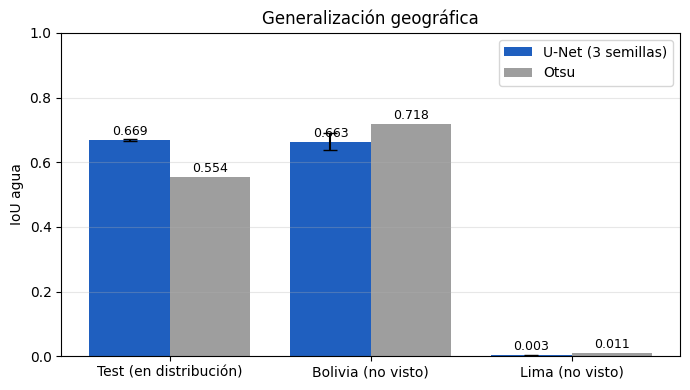

In [12]:
figura, eje = plt.subplots(figsize=(7, 4))
x = np.arange(len(tabla_brecha))
eje.bar(x - 0.2, tabla_brecha['iou'], 0.4, yerr=tabla_brecha['iou_desv'], capsize=5, color='#1f5fbf', label='U-Net (3 semillas)')
eje.bar(x + 0.2, tabla_brecha['iou_otsu'], 0.4, color='#9e9e9e', label='Otsu')
for i, (u, o) in enumerate(zip(tabla_brecha['iou'], tabla_brecha['iou_otsu'])):
    eje.text(i - 0.2, u + 0.015, f'{u:.3f}', ha='center', fontsize=9); eje.text(i + 0.2, o + 0.015, f'{o:.3f}', ha='center', fontsize=9)
eje.set_xticks(x, ['Test (en distribución)', 'Bolivia (no visto)', 'Lima (no visto)'])
eje.set_ylabel('IoU agua'); eje.set_ylim(0, 1); eje.legend(); eje.grid(alpha=0.3, axis='y')
eje.set_title('Generalización geográfica')
figura.tight_layout(); figura.savefig(DIR_FIGURAS / 'f8_brecha_regiones.png', dpi=150, bbox_inches='tight')

## 7. Matriz de confusión en Lima (suma de semillas)

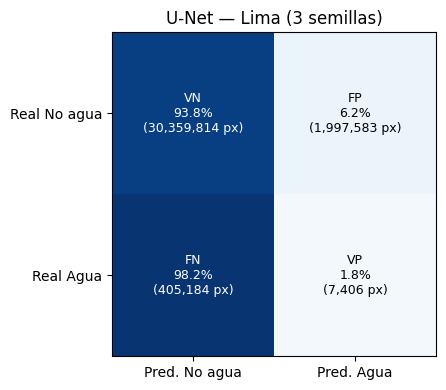

In [13]:
figura_matriz_confusion(matriz_sumada(salida['acumuladores']['lima']), 'U-Net — Lima (3 semillas)',
                        DIR_FIGURAS / 'f8_matriz_confusion_lima.png');

## 8. ¿Ayudaría otro umbral en Lima? (solo diagnóstico, NO se usa para reportar)
Si el máximo de la curva de Lima está muy lejos de 0.5, es otra señal del **cambio de dominio** (el modelo está "poco seguro" del agua de Lima).

bolivia: IoU medio a 0.5 = 0.663 | máximo 0.692 en umbral 0.090
lima: IoU medio a 0.5 = 0.003 | máximo 0.009 en umbral 0.005


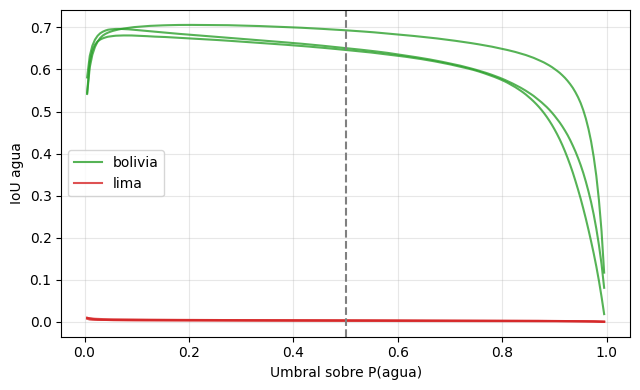

In [14]:
figura, eje = plt.subplots(figsize=(6.5, 4))
for region, color in [('bolivia', '#2ca02c'), ('lima', '#d62728')]:
    for k, (semilla, curva) in enumerate(salida['curvas'][region].items()):
        eje.plot(curva['umbral'], curva['iou'], color=color, alpha=0.8, label=region if k == 0 else None)
    mejor = pd.concat(salida['curvas'][region].values()).groupby('umbral')['iou'].mean()
    print(f"{region}: IoU medio a 0.5 = {mejor.iloc[np.abs(mejor.index.values - 0.5).argmin()]:.3f} | "
          f"máximo {mejor.max():.3f} en umbral {mejor.idxmax():.3f}")
eje.axvline(0.5, ls='--', color='gray'); eje.set_xlabel('Umbral sobre P(agua)'); eje.set_ylabel('IoU agua')
eje.legend(); eje.grid(alpha=0.3); figura.tight_layout()
figura.savefig(DIR_FIGURAS / 'f8_curva_umbral_regiones.png', dpi=150, bbox_inches='tight')

## 9. Mapas de error en Lima (semilla 42): los 4 chips con más agua

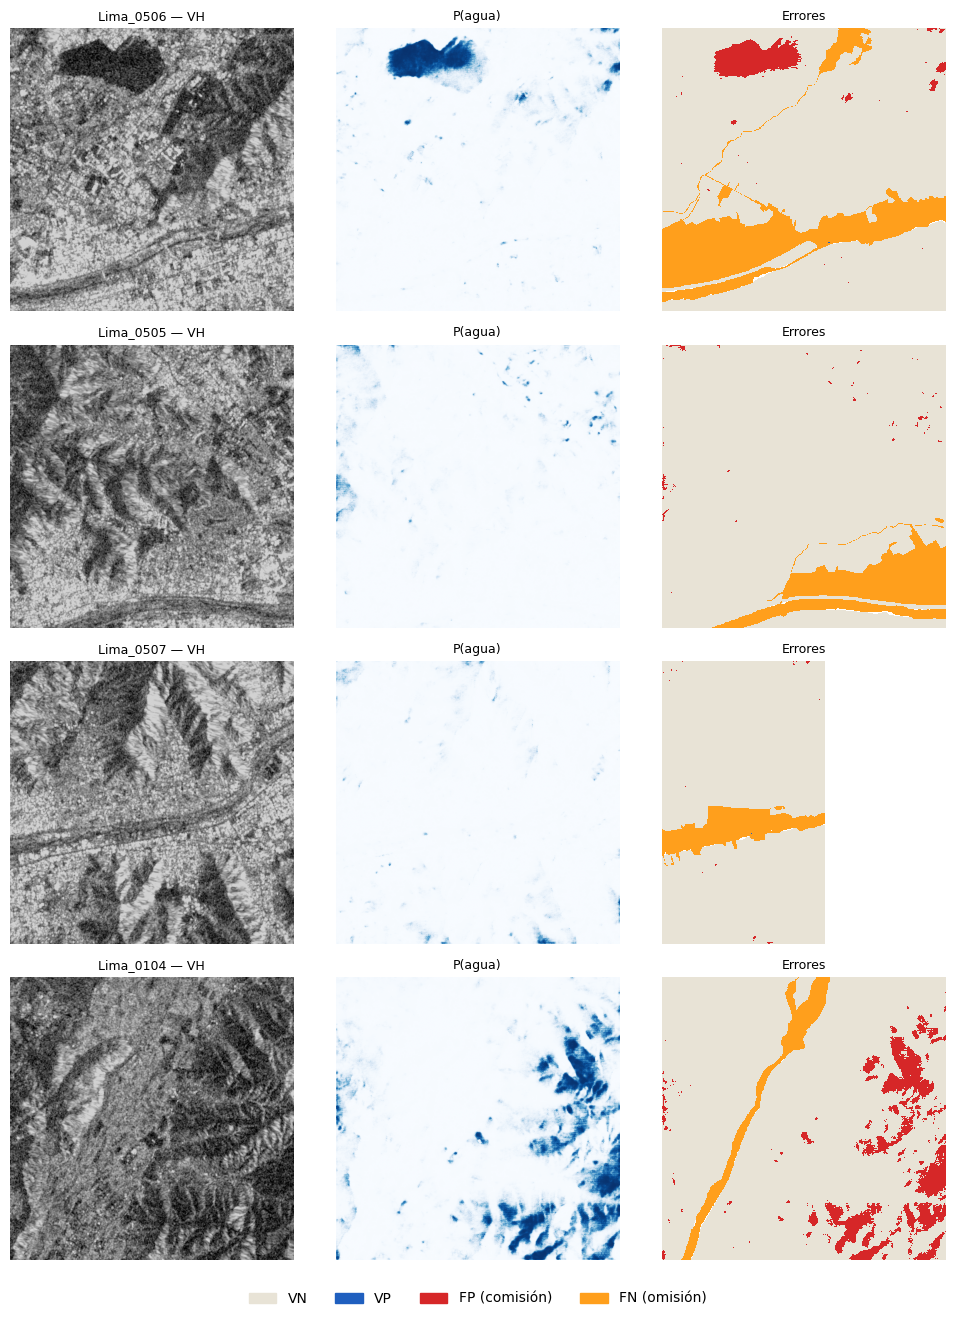

In [15]:
from src.entrenamiento import cargar_mejor_modelo
modelo, _, _ = cargar_mejor_modelo(DIR_EXPERIMENTOS / f'{carpeta_final}_s42', dispositivo)
chips_lima = pd.read_csv(DIR_RESULTADOS / 'f8_chips_lima.csv').sort_values('px_agua', ascending=False)['id_chip'].head(4)
ejemplos = []
for id_chip in chips_lima:
    i = conjunto_lima.ids_chips.index(id_chip)
    imagen, etiqueta, _ = conjunto_lima[i]
    ejemplos.append((id_chip, imagen[1].numpy(), etiqueta.numpy(), predecir_probabilidades(modelo, imagen, dispositivo).numpy()))
figura_errores(ejemplos, ruta_guardado=DIR_FIGURAS / 'f8_mapas_error_lima.png');

## 10. Mapas de error en Bolivia (semilla 42)

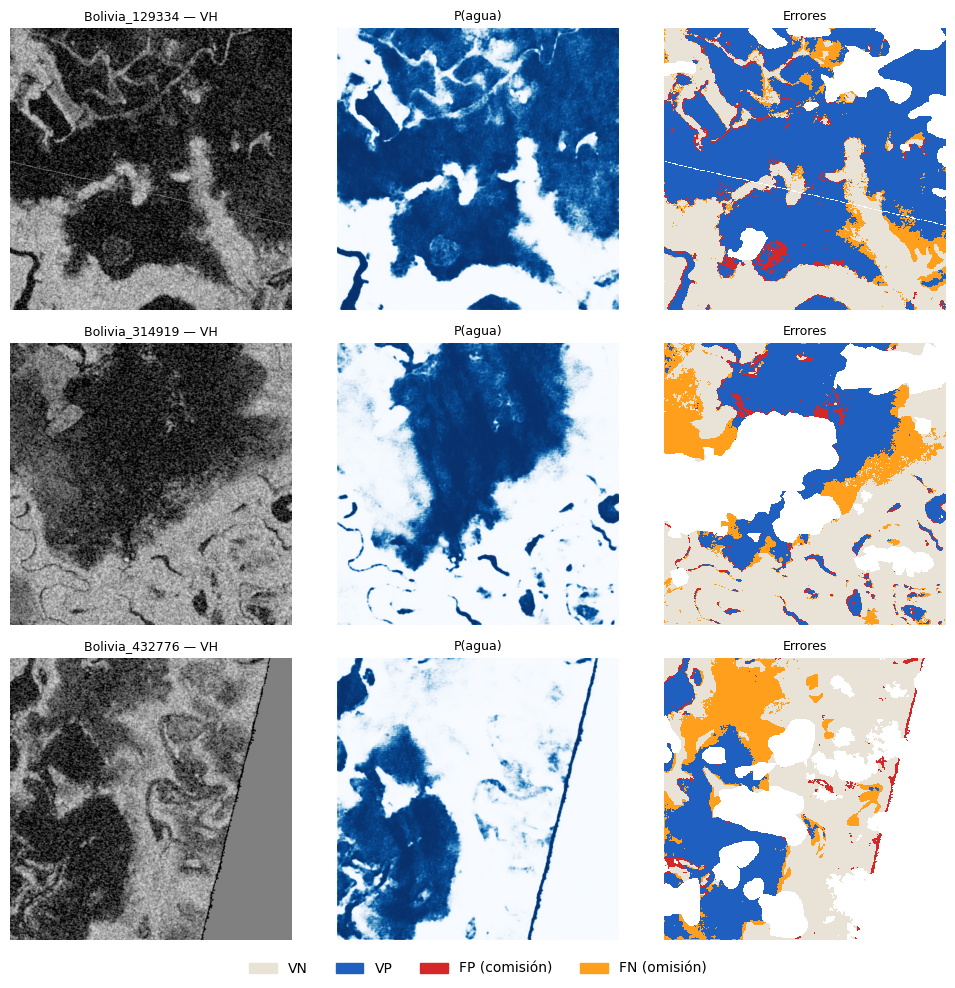

In [16]:
conjunto_bolivia = cargadores['bolivia'].dataset
orden = np.argsort([-(etq == 1).mean() for _, etq in conjunto_bolivia.cache])[:3]
ejemplos = []
for i in orden:
    imagen, etiqueta, id_chip = conjunto_bolivia[int(i)]
    ejemplos.append((id_chip, imagen[1].numpy(), etiqueta.numpy(), predecir_probabilidades(modelo, imagen, dispositivo).numpy()))
figura_errores(ejemplos, ruta_guardado=DIR_FIGURAS / 'f8_mapas_error_bolivia.png');

## Para traer a la conversación
Diagnóstico de ceros (3) y tabla de distribución corregida, tablas de 4 y 5, **tabla de la brecha (6)** y su gráfico, la matriz de Lima (7), la salida/curvas de umbral (8) y los mapas de error (9, 10).
Con eso redactamos el entregable 4 (brecha + hipótesis) y pasamos al análisis de fallos (entregable 5).

In [18]:
import sys
from pathlib import Path
import pandas as pd
import ee
from shapely.geometry import mapping

RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))
from src.configuracion import DIR_RESULTADOS
from src.lima_chips import preparar_geometrias

try:
    ee.Initialize(project='rnap-inundaciones')
except Exception:
    ee.Authenticate()                      # cuenta de la UNI
    ee.Initialize(project='rnap-inundaciones')

DIR_LIMA = RAIZ_PROYECTO / 'datos_lima'
escenas = pd.read_csv(DIR_RESULTADOS / 'f8_escenas_s1_lima.csv')
dir_ems = next((DIR_LIMA / 'emsn038').rglob('EMSN038_UTM18S_v0.gdb')).parent
geometrias = preparar_geometrias(dir_ems, cauce='ignorar')

def mediana_s1(id_escena, geometria):
    img = ee.Image(f"COPERNICUS/S1_GRD/{id_escena}").select(['VV', 'VH'])
    return img.reduceRegion(ee.Reducer.median(), ee.Geometry(mapping(geometria)),
                            scale=10, maxPixels=1e9).getInfo()

es_vh = escenas['polarizaciones'].str.contains('VH') & (escenas['orbita_relativa'] == 171)
fechas = {'05/03 antes': '2017-03-05', '17/03 durante': '2017-03-17', '29/03 después': '2017-03-29'}
ids = {nombre: escenas[es_vh & escenas['fecha_hora'].str.startswith(f)].iloc[0]['id'] for nombre, f in fechas.items()}

inundado = geometrias['inundacion']
seco = geometrias['observado'].difference(inundado.buffer(0.005))      # excluye un anillo de ~500 m
filas = [{'fecha': nombre, 'zona': zona, **mediana_s1(id_escena, geom)}
         for nombre, id_escena in ids.items()
         for zona, geom in [('inundada', inundado), ('no inundada', seco)]]
tabla_cambio = pd.DataFrame(filas).pivot(index='fecha', columns='zona', values=['VV', 'VH']).round(2)
tabla_cambio.to_csv(DIR_RESULTADOS / 'f8_cambio_temporal_lima.csv')
tabla_cambio

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


VV                   VH            
zona          inundada no inundada inundada no inundada
fecha                                                  
05/03 antes      -9.63       -9.75   -17.12      -17.25
17/03 durante    -8.75       -9.75   -16.75      -17.50
29/03 después    -9.63       -9.75   -17.37      -17.25